In [1]:
import os
import SimpleITK as sitk
from collections import Counter

def check_dataset_shapes(images_dir):
    image_files = [f for f in os.listdir(images_dir) if f.endswith(".mha")]
    shapes = []

    for file in image_files:
        image_path = os.path.join(images_dir, file)
        image = sitk.ReadImage(image_path)
        array = sitk.GetArrayFromImage(image)  # [Z, H, W]
        
        # Sadece slice boyutları önemli (H, W)
        shapes.append(array.shape[1:])

    shape_counts = Counter(shapes)

    print("📊 Dataset içindeki slice boyut dağılımı:")
    for shape, count in shape_counts.items():
        print(f"Boyut: {shape}  →  {count} adet")

    return shape_counts


In [3]:
check_dataset_shapes(r"C:\Users\user\Desktop\TeethSegmentation\ToothFairy2_DataSet\imagesTr")

📊 Dataset içindeki slice boyut dağılımı:
Boyut: (512, 512)  →  10 adet
Boyut: (410, 410)  →  53 adet
Boyut: (352, 370)  →  3 adet
Boyut: (319, 370)  →  4 adet
Boyut: (301, 370)  →  2 adet
Boyut: (356, 371)  →  1 adet
Boyut: (334, 371)  →  2 adet
Boyut: (371, 370)  →  29 adet
Boyut: (309, 370)  →  3 adet
Boyut: (306, 370)  →  2 adet
Boyut: (289, 370)  →  2 adet
Boyut: (332, 462)  →  2 adet
Boyut: (279, 370)  →  1 adet
Boyut: (282, 371)  →  2 adet
Boyut: (337, 371)  →  3 adet
Boyut: (294, 370)  →  1 adet
Boyut: (370, 370)  →  34 adet
Boyut: (277, 370)  →  2 adet
Boyut: (265, 370)  →  1 adet
Boyut: (295, 370)  →  4 adet
Boyut: (324, 371)  →  1 adet
Boyut: (369, 370)  →  4 adet
Boyut: (283, 370)  →  1 adet
Boyut: (370, 371)  →  23 adet
Boyut: (341, 463)  →  1 adet
Boyut: (286, 370)  →  4 adet
Boyut: (371, 371)  →  15 adet
Boyut: (326, 371)  →  1 adet
Boyut: (397, 463)  →  1 adet
Boyut: (342, 370)  →  4 adet
Boyut: (300, 370)  →  3 adet
Boyut: (369, 371)  →  5 adet
Boyut: (285, 370)  →  1 a

Counter({(410, 410): 53,
         (370, 370): 34,
         (371, 370): 29,
         (370, 371): 23,
         (371, 371): 15,
         (512, 512): 10,
         (317, 370): 6,
         (369, 371): 5,
         (319, 370): 4,
         (295, 370): 4,
         (369, 370): 4,
         (286, 370): 4,
         (342, 370): 4,
         (324, 370): 4,
         (321, 370): 4,
         (352, 370): 3,
         (309, 370): 3,
         (337, 371): 3,
         (300, 370): 3,
         (379, 462): 3,
         (332, 370): 3,
         (336, 371): 3,
         (298, 371): 3,
         (299, 370): 3,
         (302, 370): 3,
         (338, 370): 3,
         (322, 370): 3,
         (362, 371): 3,
         (281, 370): 3,
         (315, 370): 3,
         (301, 370): 2,
         (334, 371): 2,
         (306, 370): 2,
         (289, 370): 2,
         (332, 462): 2,
         (282, 371): 2,
         (277, 370): 2,
         (371, 462): 2,
         (336, 463): 2,
         (310, 371): 2,
         (363, 462): 2,
         (

In [45]:
import os
import numpy as np

def check_shapes(directory):
    shapes = []
    files = sorted(os.listdir(directory))
    for file in files:
        if file.endswith(".npy"):
            array = np.load(os.path.join(directory, file))
            shapes.append(array.shape)
    return shapes

train_image_shapes = check_shapes(r"C:\Users\user\Desktop\TeethSegmentation\2D_dataset\\images")
train_mask_shapes = check_shapes(r"C:\Users\user\Desktop\TeethSegmentation\2D_dataset\\masks")

print("Train image shapes:", set(train_image_shapes))
print("Train mask shapes:", set(train_mask_shapes))

Train image shapes: {(410, 410)}
Train mask shapes: {(410, 410)}


In [46]:
import os
import numpy as np
import matplotlib.pyplot as plt

def check_and_show_invalid_images(images_dir, expected_shape=(410, 410)):
    image_files = sorted([f for f in os.listdir(images_dir) if f.endswith(".npy")])

    for file in image_files:
        path = os.path.join(images_dir, file)
        image = np.load(path)

        if image.shape != expected_shape:
            print(f"⚠️ HATALI: {file} - Shape: {image.shape}")
            
            plt.figure(figsize=(6, 6))
            plt.imshow(image, cmap="gray")
            plt.title(f"Hatalı: {file} {image.shape}")
            plt.axis("off")
            plt.show()

check_and_show_invalid_images(
    images_dir=r"C:\Users\user\Desktop\TeethSegmentation\2D_dataset\\images",
    expected_shape=(410, 410)
)

In [4]:
import SimpleITK as sitk
import matplotlib.pyplot as plt

def show_mha_slice(mha_path, slice_index=None, cmap="gray"):
    # MHA dosyasını oku
    image = sitk.ReadImage(mha_path)
    image_np = sitk.GetArrayFromImage(image)  # [Z, H, W]

    print(f"📐 Orijinal 3D Image shape: {image_np.shape}")  # (Z, H, W)

    # Eğer slice seçilmemişse ortadaki slice'ı göster
    if slice_index is None:
        slice_index = image_np.shape[0] // 2

    # Slice seçimini kontrol et
    if slice_index >= image_np.shape[0] or slice_index < 0:
        raise ValueError(f"Slice index {slice_index} geçersiz. Toplam slice: {image_np.shape[0]}")

    # İstediğin slice'ı al
    slice_2d = image_np[slice_index]

    # Görüntüle
    plt.figure(figsize=(6, 6))
    plt.imshow(slice_2d, cmap=cmap)
    plt.title(f"Slice {slice_index}")
    plt.axis("off")
    plt.show()


📐 Orijinal 3D Image shape: (274, 410, 410)


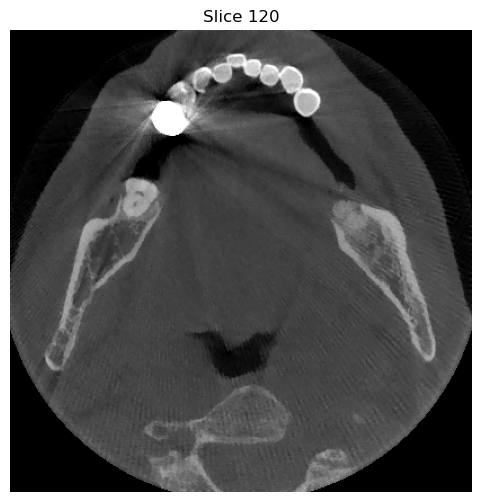

In [42]:
show_mha_slice(
    mha_path=r"C:\Users\user\Desktop\TeethSegmentation\ToothFairy2_DataSet\imagesTr\ToothFairy2F_015_0000.mha",
    slice_index=120  # hangi slice'ı görmek istiyorsan
)


In [43]:
import os
import numpy as np
import SimpleITK as sitk

def check_teeth_classes_in_volume(masks_dir):
    upper_teeth = {11, 12, 13, 14, 15, 16, 17, 18,
                   21, 22, 23, 24, 25, 26, 27, 28}
    
    lower_teeth = {31, 32, 33, 34, 35, 36, 37, 38,
                   41, 42, 43, 44, 45, 46, 47, 48}

    mask_files = sorted([f for f in os.listdir(masks_dir) if f.endswith(".mha")])

    for file in mask_files:
        mask_path = os.path.join(masks_dir, file)
        mask_3d = sitk.GetArrayFromImage(sitk.ReadImage(mask_path)).astype(np.uint8)

        unique_classes = set(np.unique(mask_3d))
        has_upper = bool(upper_teeth & unique_classes)
        has_lower = bool(lower_teeth & unique_classes)

        print(f"📂 {file}: Upper Teeth: {has_upper}, Lower Teeth: {has_lower}, Classes: {sorted(unique_classes)}")



In [44]:
check_teeth_classes_in_volume(
    masks_dir=r"C:\Users\user\Desktop\TeethSegmentation\ToothFairy2_DataSet\labelsTr"
)

📂 ToothFairy2F_001.mha: Upper Teeth: True, Lower Teeth: True, Classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 21, 22, 23, 24, 25, 27, 31, 32, 33, 34, 35, 41, 42, 43, 44, 45, 47]
📂 ToothFairy2F_002.mha: Upper Teeth: True, Lower Teeth: True, Classes: [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 14, 15, 16, 21, 22, 23, 24, 26, 27, 31, 32, 33, 34, 37, 41, 42, 43, 44, 45]
📂 ToothFairy2F_003.mha: Upper Teeth: True, Lower Teeth: True, Classes: [0, 1, 2, 3, 4, 5, 6, 7, 9, 10, 11, 12, 13, 21, 22, 23, 24, 25, 26, 27, 31, 32, 33, 38, 41, 42, 43, 44, 45]
📂 ToothFairy2F_004.mha: Upper Teeth: True, Lower Teeth: True, Classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 13, 14, 15, 18, 21, 22, 23, 24, 25, 26, 27, 31, 32, 33, 34, 35, 41, 42, 43, 44, 45, 46, 47, 48]
📂 ToothFairy2F_005.mha: Upper Teeth: True, Lower Teeth: True, Classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 18, 21, 22, 23, 24, 25, 26, 31, 32, 33, 34, 35, 37, 41, 42, 43, 44, 45, 46, 47, 48]
📂 ToothFairy2F_006.mha: 

KeyboardInterrupt: 